In [2]:
# ============================================================
# 0. IMPORT DASAR
#    (JANGAN atur logging flwr di sini, karena akan ditimpa
#     saat flwr di-import di cell 6)
# ============================================================
from pathlib import Path
 
import numpy as np
import pandas as pd
 
from dataset import prepare_client_data, TARGET, DROP_COLS
 
# ============================================================
# 1. KONFIGURASI
# ============================================================
CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')
 
# ============================================================
# 2. MUAT DATA SEMUA CLIENT (scaling + konversi ke tensor)
# ============================================================
clients, scaler, feature_names = prepare_client_data(CLIENT_DIR)
 
print(f"Jumlah client : {len(clients)}")
print(f"Daftar state  : {list(clients.keys())}")
print(f"Target        : {TARGET}")
print(f"Kolom dibuang : {DROP_COLS}")
 
# ============================================================
# 3. DAFTAR FITUR YANG DIPAKAI
# ============================================================
n_fitur = next(iter(clients.values()))['X_train_t'].shape[1]
assert n_fitur == len(feature_names), "Jumlah fitur tidak cocok dengan nama fitur"
 
print(f"\nJumlah fitur  : {n_fitur}")
for i, nama in enumerate(feature_names, 1):
    print(f"{i:>3}. {nama}")
 
# ============================================================
# 4. RINGKASAN TIAP CLIENT
# ============================================================
rows = {}
for st, c in clients.items():
    rows[st] = {
        'n_train':   len(c['y_train_t']),
        'n_val':     len(c['y_val_t']),
        'n_test':    len(c['y_test_t']),
        'pos_train': int(c['y_train_t'].sum()),
        'pos_val':   int(c['y_val_t'].sum()),
        'pos_test':  int(c['y_test_t'].sum()),
    }
 
ringkas = pd.DataFrame(rows).T
ringkas.index.name = 'state'
 
for s in ('train', 'val', 'test'):
    ringkas[f'pos_{s}_%'] = (100 * ringkas[f'pos_{s}'] / ringkas[f'n_{s}']).round(2)
 
total = ringkas[[c for c in ringkas.columns if not c.endswith('%')]].sum()
for s in ('train', 'val', 'test'):
    total[f'pos_{s}_%'] = round(100 * total[f'pos_{s}'] / total[f'n_{s}'], 2)
ringkas.loc['TOTAL'] = total
 
print("\nRingkasan per client:")
print(ringkas.to_string())
 

Jumlah client : 44
Daftar state  : [1, 2, 4, 5, 8, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 22, 23, 24, 25, 26, 27, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 44, 45, 46, 48, 49, 50, 51, 53, 54, 55, 56]
Target        : _michd
Kolom dibuang : ['iyear', '_state', 'cvdinfr4', 'cvdcrhd4']

Jumlah fitur  : 69
  1. sexvar
  2. _age80
  3. _educag
  4. income3
  5. veteran3
  6. children
  7. _urbstat
  8. _bmi5
  9. diabete4
 10. medcost1
 11. checkup1
 12. genhlth
 13. physhlth
 14. menthlth
 15. exerany2
 16. cvdstrk3
 17. chcscnc1
 18. chcocnc1
 19. chccopd3
 20. addepev3
 21. chckdny2
 22. havarth4
 23. diabage4
 24. deaf
 25. blind
 26. decide
 27. diffwalk
 28. diffdres
 29. diffalon
 30. _rfbing6
 31. drnkany6
 32. flushot7
 33. pneuvac4
 34. marital_1
 35. marital_2
 36. marital_3
 37. marital_4
 38. marital_5
 39. marital_6
 40. employ1_1
 41. employ1_2
 42. employ1_3
 43. employ1_4
 44. employ1_5
 45. employ1_6
 46. employ1_7
 47. employ1_8
 48. renthom1_1
 49. renthom1_2
 50. 

Client: ['state_1', 'state_2', 'state_4', 'state_5', 'state_8', 'state_10', 'state_11', 'state_12', 'state_13', 'state_15', 'state_16', 'state_17', 'state_18', 'state_19', 'state_20', 'state_22', 'state_23', 'state_24', 'state_25', 'state_26', 'state_27', 'state_29', 'state_30', 'state_31', 'state_33', 'state_34', 'state_35', 'state_36', 'state_37', 'state_38', 'state_39', 'state_40', 'state_41', 'state_44', 'state_45', 'state_46', 'state_48', 'state_49', 'state_50', 'state_51', 'state_53', 'state_54', 'state_55', 'state_56']
n_features per client: {'state_1': 69, 'state_2': 69, 'state_4': 69, 'state_5': 69, 'state_8': 69, 'state_10': 69, 'state_11': 69, 'state_12': 69, 'state_13': 69, 'state_15': 69, 'state_16': 69, 'state_17': 69, 'state_18': 69, 'state_19': 69, 'state_20': 69, 'state_22': 69, 'state_23': 69, 'state_24': 69, 'state_25': 69, 'state_26': 69, 'state_27': 69, 'state_29': 69, 'state_30': 69, 'state_31': 69, 'state_33': 69, 'state_34': 69, 'state_35': 69, 'state_36': 69, '

2026-10-21 15:26:06,093	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


Varian pairwise:
  t0.1_d0.0    {'temperature': 0.1, 'data_influence': 0.0}
  t0.1_d0.3    {'temperature': 0.1, 'data_influence': 0.3}
  t0.1_d0.5    {'temperature': 0.1, 'data_influence': 0.5}
  t0.01_d0.0   {'temperature': 0.01, 'data_influence': 0.0}
  t0.01_d0.3   {'temperature': 0.01, 'data_influence': 0.3}
  t0.01_d0.5   {'temperature': 0.01, 'data_influence': 0.5}
[0.0, 0.0] {'theta_size_mb': 0.0238037109375, 'total_up_mb': 2.0947265625, 'total_down_mb': 2.0947265625, 'total_mb': 4.189453125, 'avg_per_round_mb': 2.0947265625, 'avg_per_client_mb': 0.09521484375, 'full_total_mb': 7.2415771484375, 'saving_pct': 42.147227888002966}
[exp|alt|pairwise|T0.01|DI0.3] round 01 | loss=0.5328 acc=0.7825 prec=0.1906 rec=0.0093 f1=0.0157 auc=0.6926 | comm=2.095MB (cum 2.095MB)
[exp|alt|pairwise|T0.01|DI0.3] round 02 | loss=0.4991 acc=0.7553 prec=0.4517 rec=0.3869 f1=0.3934 auc=0.7244 | comm=2.095MB (cum 4.189MB)
[exp|alt|pairwise|T0.01|DI0.3] round 03 | loss=0.5107 acc=0.7444 prec=0.4191 rec=

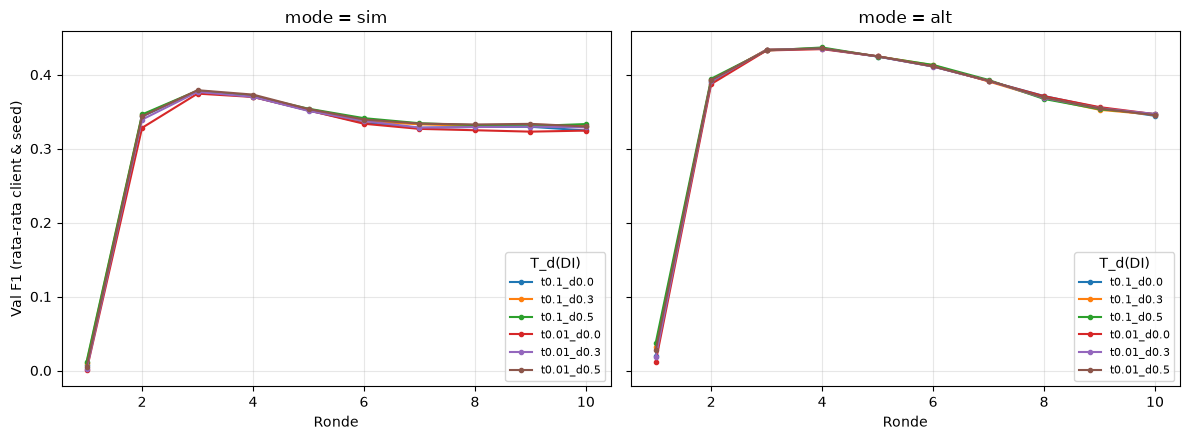

In [3]:
# %%
# ============================================================
# 5. KONVERSI clients -> fed_data (format yang diminta fl_runner)
# ============================================================
fed_data = {}
for st, c in clients.items():
    fed_data[f"state_{st}"] = {
        "X_train": c["X_train_t"], "y_train": c["y_train_t"],
        "X_val":   c["X_val_t"],   "y_val":   c["y_val_t"],
        "X_test":  c["X_test_t"],  "y_test":  c["y_test_t"],
        "n_features": c["X_train_t"].shape[1],
    }
 
print("Client:", list(fed_data.keys()))
print("n_features per client:", {k: v["n_features"] for k, v in fed_data.items()})
 
# %%
# ============================================================
# 6. IMPORT RUNNER + REDAM LOG
#    fl_running1.py, model.py, aggregation4.py harus satu folder
#    dengan script ini (atau ada di sys.path).
# ============================================================
import importlib
import logging
import contextlib
 
import fl_running1 as fl
importlib.reload(fl)                     # supaya perubahan file langsung terbaca
 
# --- Redam log Flower SETELAH flwr ter-import ---
flwr_logger = logging.getLogger("flwr")
for h in flwr_logger.handlers:           # console hanya WARNING ke atas
    h.setLevel(logging.WARNING)
 
# detail lengkap tetap disimpan ke file (hindari handler dobel saat cell dijalankan ulang)
if not any(isinstance(h, logging.FileHandler) for h in flwr_logger.handlers):
    fh = logging.FileHandler("fl_run.log", encoding="utf-8")
    fh.setLevel(logging.INFO)
    fh.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
    flwr_logger.addHandler(fh)
flwr_logger.setLevel(logging.INFO)
 
 
# --- Alihkan print() dari runner (baris "[cmp|alt|...] round 03 ...") ke file ---
@contextlib.contextmanager
def quiet(logfile="fl_prints.log"):
    with open(logfile, "a", encoding="utf-8") as f, contextlib.redirect_stdout(f):
        yield
 
 
run_federated          = fl.run_federated
run_pairwise_variants  = fl.run_pairwise_variants
summarize_variants     = fl.summarize_variants
print_comparison       = fl.print_comparison
print_seed_summary     = fl.print_seed_summary
export_history_csv     = fl.export_history_csv
export_per_client_csv  = fl.export_per_client_csv
export_variants        = fl.export_variants
PAIRWISE_VARIANTS      = fl.PAIRWISE_VARIANTS
 
COMMON_DIM = 64      # dimensi bersama untuk theta, sesuaikan dengan build_model
N_CLASSES  = 2
 
print("Varian pairwise:")
for k, v in PAIRWISE_VARIANTS.items():
    print(f"  {k:<12} {v}")
 
# %%
# ============================================================
# 7. TES CEPAT (sanity check): 2 ronde, 1 epoch, 1 varian
# ============================================================
with quiet():
    h_test = run_federated(
        fed_data, name="smoke",
        common_dim=COMMON_DIM, n_classes=N_CLASSES,
        num_rounds=2, local_epochs=1,
        mode="sim",
        strategy_kwargs=dict(temperature=0.01, data_influence=0.3),
        verbose_report=False,
    )
print(h_test["f1"], h_test["comm"])
 
# %%
# ============================================================
# 8. JALANKAN SATU KONFIGURASI PENUH (laporan lengkap)
#    Tidak dibungkus quiet() karena verbose_report=True
#    memang sengaja mencetak laporan.
# ============================================================
history = run_federated(
    fed_data, name="exp",
    common_dim=COMMON_DIM, n_classes=N_CLASSES,
    num_rounds=10, local_epochs=5, batch_size=64, lr=1e-3,
    mode="alt",
    epochs_v=3, epochs_u=2,
    strategy_kwargs=dict(temperature=0.01, data_influence=0.3),
    select_by="f1",
    verbose_report=True,
)
 
print("\nTEST ronde terakhir (rata-rata client):", history["test"])
print("TEST ronde terbaik  (rata-rata client):", history.get("test_best"),
      "| best_round =", history.get("best_round"))
 
# %%
# ============================================================
# 9. BANDINGKAN 6 VARIAN PAIRWISE (temperature x data_influence)
#    per mode (sim / alt). seeds > 1 -> hasil dirata-rata (mean ± std)
#
#    Jumlah run = len(MODES) x 6 varian x len(SEEDS).
#    Untuk uji awal: MODES = ("sim",) dan SEEDS = (42,).
# ============================================================
NUM_ROUNDS   = 10
LOCAL_EPOCHS = 5
SEEDS        = (42, 1)
MODES        = ("sim", "alt")
 
all_hist = {}                 # {"sim": {varian: history}, "alt": {...}}
for mode in MODES:
    print(f"MODE: {mode} ...", end=" ", flush=True)
    extra = dict(epochs_v=3, epochs_u=2) if mode == "alt" else {}
    with quiet():             # log per-ronde masuk ke fl_prints.log
        all_hist[mode] = run_pairwise_variants(
            fed_data, name="cmp", common_dim=COMMON_DIM,
            seeds=SEEDS,
            n_classes=N_CLASSES,
            num_rounds=NUM_ROUNDS, local_epochs=LOCAL_EPOCHS,
            mode=mode,
            select_by="f1",
            **extra,
        )
    print("selesai")
 
 
def _mean_over_runs(runs, split, key):
    vals = [r[split][key] for r in runs if r.get(split)]
    return float(np.nanmean(vals)) if vals else None
 
 
# Tabel ringkasan (satu baris per mode+varian; rata-rata antar seed)
rows = []
for mode, hs in all_hist.items():
    for vname, h in hs.items():
        runs = h.get("runs", [h])
        vp = h["variant_params"]
        last_f1 = [r["f1"][-1] for r in runs if r["f1"]]
        rows.append({
            "config":       f"{mode}+{vname}",
            "temperature":  vp["temperature"],
            "data_infl":    vp["data_influence"],
            "val_f1_last":  float(np.mean(last_f1)) if last_f1 else None,
            "test_acc":     _mean_over_runs(runs, "test", "accuracy"),
            "test_prec":    _mean_over_runs(runs, "test", "precision"),
            "test_rec":     _mean_over_runs(runs, "test", "recall"),
            "test_f1":      _mean_over_runs(runs, "test", "f1"),
            "test_auc":     _mean_over_runs(runs, "test", "auc"),
            "testbest_f1":  _mean_over_runs(runs, "test_best", "f1"),
            "testbest_auc": _mean_over_runs(runs, "test_best", "auc"),
            "total_MB":     float(np.mean([r["comm"]["total_mb"] for r in runs])),
        })
summary = pd.DataFrame(rows).set_index("config").round(4)
print("\n", summary.to_string())
 
# %%
# ============================================================
# 10. DETAIL KOMPARASI (per mode)
# ============================================================
BASELINE = "t0.01_d0.3"       # varian acuan untuk kolom delta
 
for mode, hs in all_hist.items():
    print(f"\n######## {mode} : ronde terbaik (val) ########")
    summarize_variants(hs, split="test_best")           # mean ± std, urut F1
    print_comparison(hs, split="test_best_per_client", baseline=BASELINE)
    if len(SEEDS) > 1:
        print_seed_summary(hs, split="test_best")
 
# %%
# ============================================================
# 11. EKSPOR CSV
# ============================================================
OUT_DIR = Path("hasil_fl"); OUT_DIR.mkdir(exist_ok=True)
 
for mode, hs in all_hist.items():
    mode_dir = OUT_DIR / mode
    mode_dir.mkdir(exist_ok=True)
    for vname, h in hs.items():
        tag = vname
        export_history_csv(h, str(mode_dir / f"{tag}_rounds.csv"))
        export_per_client_csv(h, str(mode_dir / f"{tag}_per_client_val.csv"))
        export_per_client_csv(h, str(mode_dir / f"{tag}_per_client_test.csv"),
                              split="test_per_client")
    # compare_test.csv, compare_rounds.csv, ringkasan_varian_best/last.csv
    export_variants(hs, str(mode_dir), baseline=BASELINE)
summary.to_csv(OUT_DIR / "summary.csv")
 
# %%
# ============================================================
# 12. PLOT KURVA F1 PER RONDE (rata-rata antar seed)
# ============================================================
import matplotlib.pyplot as plt
 
fig, axes = plt.subplots(1, len(all_hist), figsize=(6 * len(all_hist), 4.5),
                         sharey=True, squeeze=False)
for ax, (mode, hs) in zip(axes[0], all_hist.items()):
    for vname, h in hs.items():
        runs = h.get("runs", [h])
        n = min(len(r["f1"]) for r in runs)
        if n == 0:
            continue
        rounds = runs[0]["round"][:n]
        mean_f1 = np.mean([r["f1"][:n] for r in runs], axis=0)
        ax.plot(rounds, mean_f1, marker="o", markersize=3, label=vname)
    ax.set_title(f"mode = {mode}")
    ax.set_xlabel("Ronde")
    ax.grid(alpha=.3)
    ax.legend(fontsize=8, title="T_d(DI)")
axes[0][0].set_ylabel("Val F1 (rata-rata client & seed)")
plt.tight_layout()
plt.savefig(OUT_DIR / "f1_per_round.png", dpi=150)
plt.show()